# RIAWELC Weld Defect Pipeline
## Improved Generalisation to Unseen Welds
| Correction | Purpose |
|---|---|
| **Dual-view input** (full patch + YOLO ROI, shared backbone) | Keeps the YOLO detection stage while restoring the surrounding context lost by cropping |
| **Weld-balanced sampling** | Stops the largest welds from dominating what the model learns |
| **Mixup** | Smoother decision boundaries between visually similar defect types |
| **Ensemble + optional AdaBN** | Averages three backbones; AdaBN re-estimates BatchNorm statistics on unlabeled target images (no labels used) |

Model selection uses the validation welds only. The test set is evaluated once per variant and every variant is reported.

## 1. Environment Setup

### 1.1 Install Dependencies

In [1]:
!pip -q install timm

### 1.2 Import Libraries

In [2]:
import os, json, math, time, random, copy, warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, roc_auc_score, cohen_kappa_score,
                             matthews_corrcoef)
from sklearn.preprocessing import label_binarize

import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import timm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)

c:\Users\dipkh\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.3 Experiment Configuration

`INPUT_MODE`: `"dual"` (full patch + YOLO ROI), `"roi"` (YOLO crop only, as in notebooks 01–03) or `"full"` (full patch only).

In [3]:
PROJECT_DIR = Path(r"C:\Users\dipkh\Downloads\RIAWLC\3")
os.chdir(PROJECT_DIR)
OUTPUT_ROOT = PROJECT_DIR / "riawelc_outputs"
PROTOCOL    = "weld_holdout"

BACKBONES = {
    "ResNet50":        "resnet50.a1_in1k",
    "EfficientNet-B3": "efficientnet_b3.ra2_in1k",
    "ConvNeXt-Tiny":   "convnext_tiny.fb_in22k_ft_in1k",
}
INPUT_MODE      = "dual"
WELD_BALANCED   = True
MIXUP_ALPHA     = 0.2
MIXUP_PROB      = 0.5
IMG_SIZE        = 224
BATCH_SIZE      = 32
EPOCHS          = 12
FREEZE_EPOCHS   = 1
WARMUP_EPOCHS   = 1
LR_HEAD         = 1e-3
LR_BACKBONE     = 5e-5
WEIGHT_DECAY    = 0.05
LABEL_SMOOTHING = 0.1
PATIENCE        = 4
USE_TTA         = True
USE_ADABN       = True
N_BOOTSTRAP     = 1000
SEED            = 42
NUM_WORKERS     = 0 if os.name == "nt" else min(8, os.cpu_count() or 2)

SHARED  = OUTPUT_ROOT / PROTOCOL / "_shared"
OUT_DIR = OUTPUT_ROOT / PROTOCOL / f"improved_{INPUT_MODE}"
assert (SHARED / "manifest.csv").exists(), f"Run notebook 00 with PROTOCOL='{PROTOCOL}' first"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = False

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
print(f"Protocol: {PROTOCOL} | input: {INPUT_MODE} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if USE_AMP else ""))

Protocol: weld_holdout | input: dual | device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU)


## 2. Load the Prepared Dataset

In [4]:
config = json.loads((SHARED / "config.json").read_text())
CLASS_ORDER = config["class_order"]
NAMES = [config["display_names"][k] for k in CLASS_ORDER]
SHORT = [config["short_names"][k] for k in CLASS_ORDER]
NUM_CLASSES = len(CLASS_ORDER)
df = pd.read_csv(SHARED / "manifest.csv")
train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
assert not set(train_df.weld) & set(test_df.weld) or PROTOCOL != "weld_holdout"
assert not set(train_df.md5) & set(test_df.md5)
print(f"Train {len(train_df):,} ({train_df.weld.nunique()} welds) | Val {len(val_df):,} ({val_df.weld.nunique()} welds) "
      f"| Test {len(test_df):,} ({test_df.weld.nunique()} welds)")
display(pd.crosstab(df.split, df.class_name, margins=True).reindex(["train", "val", "test", "All"]))

Train 14,372 (19 welds) | Val 2,910 (6 welds) | Test 4,682 (4 welds)


class_name,Crack,Lack of Penetration,No Defect,Porosity,All
split,,,,,
train,4361,2622,3546,3843,14372
val,774,507,674,955,2910
test,1735,877,1180,890,4682
All,6870,4006,5400,5688,21964


## 3. Preprocessing, Augmentation and Data Loaders

In [5]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class PercentileStretch:
    def __call__(self, img):
        a = np.asarray(img, dtype=np.float32)
        lo, hi = np.percentile(a, 1), np.percentile(a, 99)
        return Image.fromarray((np.clip((a - lo) / max(hi - lo, 1.0), 0, 1) * 255).astype(np.uint8))

class RandomGamma:
    def __init__(self, lo=0.6, hi=1.6, p=0.7): self.lo, self.hi, self.p = lo, hi, p
    def __call__(self, img):
        if random.random() > self.p: return img
        g = math.exp(random.uniform(math.log(self.lo), math.log(self.hi)))
        return Image.fromarray(((np.asarray(img, dtype=np.float32) / 255.0) ** g * 255).astype(np.uint8))

class AddGaussianNoise:
    def __init__(self, std=(0.0, 0.05), p=0.4): self.std, self.p = std, p
    def __call__(self, t):
        return t if random.random() > self.p else t + torch.randn_like(t) * random.uniform(*self.std)

class ToThreeChannels:
    def __call__(self, t):
        return t.repeat(3, 1, 1) if t.shape[0] == 1 else t

train_tfm = T.Compose([
    PercentileStretch(), RandomGamma(), T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.3),
    T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToTensor(), AddGaussianNoise(), ToThreeChannels(), T.Normalize(MEAN, STD)])
eval_tfm = T.Compose([PercentileStretch(), T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), ToThreeChannels(),
                      T.Normalize(MEAN, STD)])

VIEW_COLS = {"dual": ["path", "cls_path"], "roi": ["cls_path"], "full": ["path"]}[INPUT_MODE]

class MultiViewDataset(Dataset):
    def __init__(self, frame, tfm):
        self.views = [frame[c].tolist() for c in VIEW_COLS]
        self.labels, self.tfm = frame.label.tolist(), tfm
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        xs = [self.tfm(Image.open(v[i]).convert("L")) for v in self.views]
        return (*xs, self.labels[i])

def make_loader(frame, train):
    kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=NUM_WORKERS > 0)
    if not train:
        return DataLoader(MultiViewDataset(frame, eval_tfm), shuffle=False, **kw)
    ds = MultiViewDataset(frame, train_tfm)
    g = torch.Generator().manual_seed(SEED)
    if WELD_BALANCED:
        cell = frame.groupby(["weld", "label"]).label.transform("size").values
        w = 1.0 / np.sqrt(cell)
        sampler = WeightedRandomSampler(torch.tensor(w, dtype=torch.double), num_samples=len(frame),
                                        replacement=True, generator=g)
        return DataLoader(ds, sampler=sampler, drop_last=True, **kw)
    return DataLoader(ds, shuffle=True, drop_last=True, generator=g, **kw)

train_loader, val_loader, test_loader = make_loader(train_df, True), make_loader(val_df, False), make_loader(test_df, False)
counts = np.bincount(train_df.label, minlength=NUM_CLASSES).clip(min=1)
class_w = torch.tensor((counts.sum() / (NUM_CLASSES * counts)) ** 0.5, dtype=torch.float32, device=DEVICE)
sample = train_loader.dataset[0]
print(f"Views per sample: {len(sample) - 1} ({', '.join(VIEW_COLS)}) | tensor {tuple(sample[0].shape)} "
      f"| weld-balanced: {WELD_BALANCED}")

Views per sample: 2 (path, cls_path) | tensor (3, 224, 224) | weld-balanced: True


## 4. Dual-View Model and Training Routine

In [6]:
class MultiViewNet(nn.Module):
    def __init__(self, timm_name, n_views):
        super().__init__()
        self.backbone = timm.create_model(timm_name, pretrained=True, num_classes=0, drop_path_rate=0.1)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(self.backbone.num_features * n_views, NUM_CLASSES))
    def forward(self, *views):
        return self.head(torch.cat([self.backbone(v) for v in views], 1))

def to_device(batch):
    *xs, y = batch
    return [x.to(DEVICE, non_blocking=True) for x in xs], y.to(DEVICE, non_blocking=True)

def run_epoch(model, loader, crit, opt=None, sched=None, scaler=None):
    train = opt is not None
    model.train(train)
    tot, n, ys, ps = 0.0, 0, [], []
    for batch in loader:
        xs, y = to_device(batch)
        mix = train and MIXUP_ALPHA > 0 and random.random() < MIXUP_PROB
        if mix:
            lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))
            perm = torch.randperm(y.size(0), device=DEVICE)
            xs = [lam * x + (1 - lam) * x[perm] for x in xs]
        with torch.set_grad_enabled(train), torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(*xs)
            loss = lam * crit(logits, y) + (1 - lam) * crit(logits, y[perm]) if mix else crit(logits, y)
        if train:
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * y.size(0); n += y.size(0)
        ys.append(y.cpu()); ps.append(logits.argmax(1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return tot / n, accuracy_score(y, p), f1_score(y, p, average="macro")

def fit(key, timm_name):
    seed_everything()
    model = MultiViewNet(timm_name, len(VIEW_COLS)).to(DEVICE)
    backbone, head = list(model.backbone.parameters()), list(model.head.parameters())
    opt = torch.optim.AdamW([{"params": backbone, "lr": LR_BACKBONE}, {"params": head, "lr": LR_HEAD}],
                            weight_decay=WEIGHT_DECAY)
    spe = len(train_loader); total, warm = EPOCHS * spe, WARMUP_EPOCHS * spe
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = (torch.amp.GradScaler("cuda", enabled=USE_AMP) if hasattr(torch.amp, "GradScaler")
              else torch.cuda.amp.GradScaler(enabled=USE_AMP))
    crit = nn.CrossEntropyLoss(weight=class_w, label_smoothing=LABEL_SMOOTHING)
    ckpt = OUT_DIR / f"{key}_best.pt"
    best_f1, best_loss, bad, hist = -1.0, np.inf, 0, []
    for ep in range(EPOCHS):
        frozen = ep < FREEZE_EPOCHS
        for p in backbone:
            p.requires_grad = not frozen
        t0 = time.time()
        tr = run_epoch(model, train_loader, crit, opt, sched, scaler)
        va = run_epoch(model, val_loader, crit)
        hist.append(dict(epoch=ep + 1, train_loss=tr[0], train_acc=tr[1], val_loss=va[0], val_acc=va[1], val_f1=va[2]))
        improved = va[2] > best_f1 + 1e-4 or (abs(va[2] - best_f1) <= 1e-4 and va[0] < best_loss)
        if improved:
            best_f1, best_loss, bad = va[2], va[0], 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
        print(f"[{key}] Epoch {ep+1:02d}{' [head]' if frozen else '       '} | train loss {tr[0]:.4f} acc {tr[1]:.4f} "
              f"| val loss {va[0]:.4f} acc {va[1]:.4f} F1 {va[2]:.4f}{'  ✓' if improved else ''} | {time.time()-t0:.0f}s")
        if not frozen and bad >= PATIENCE:
            print(f"[{key}] Early stopping."); break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model, pd.DataFrame(hist)

@torch.no_grad()
def predict(model, loader):
    model.eval(); out = []
    for batch in loader:
        xs, _ = to_device(batch)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            views = [xs, [torch.flip(x, [3]) for x in xs], [torch.flip(x, [2]) for x in xs]] if USE_TTA else [xs]
            out.append(torch.stack([model(*v).float().softmax(1) for v in views]).mean(0).cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def adabn_predict(model, loader):
    m = copy.deepcopy(model)
    bns = [x for x in m.modules() if isinstance(x, nn.modules.batchnorm._BatchNorm)]
    if not bns:
        return None
    for b in bns:
        b.reset_running_stats(); b.momentum = None
    m.eval()
    for b in bns:
        b.train()
    for batch in loader:
        xs, _ = to_device(batch)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            m(*xs)
    m.eval()
    p = predict(m, loader)
    del m; torch.cuda.empty_cache()
    return p

## 5. Train All Backbones

In [7]:
val_probs, test_probs, histories = {}, {}, {}
for key, name in BACKBONES.items():
    pfile = OUT_DIR / f"{key}_predictions.npz"
    if pfile.exists():
        d = np.load(pfile, allow_pickle=True)
        for v in [k for k in d.files if k.startswith("val__")]:
            val_probs[v[5:]] = d[v]
        for v in [k for k in d.files if k.startswith("test__")]:
            test_probs[v[6:]] = d[v]
        print(f"[{key}] loaded saved predictions (delete {pfile.name} to retrain)")
        continue
    model, hist = fit(key, name)
    hist.to_csv(OUT_DIR / f"{key}_history.csv", index=False); histories[key] = hist
    res = {f"val__{key}": predict(model, val_loader), f"test__{key}": predict(model, test_loader)}
    if USE_ADABN:
        pv, pt = adabn_predict(model, val_loader), adabn_predict(model, test_loader)
        if pv is not None:
            res[f"val__{key} + AdaBN"], res[f"test__{key} + AdaBN"] = pv, pt
    np.savez(pfile, **res)
    for k, v in res.items():
        (val_probs if k.startswith("val__") else test_probs)[k.split("__", 1)[1]] = v
    del model; torch.cuda.empty_cache()
print("Variants:", list(test_probs))

[ResNet50] Epoch 01 [head] | train loss 1.1877 acc 0.4939 | val loss 0.9669 acc 0.6443 F1 0.6097  ✓ | 934s
[ResNet50] Epoch 02        | train loss 0.7964 acc 0.6580 | val loss 0.5988 acc 0.9045 F1 0.8832  ✓ | 753s
[ResNet50] Epoch 03        | train loss 0.6166 acc 0.7849 | val loss 0.6008 acc 0.8753 F1 0.8498 | 637s
[ResNet50] Epoch 04        | train loss 0.5861 acc 0.7643 | val loss 0.6395 acc 0.8660 F1 0.8437 | 632s
[ResNet50] Epoch 05        | train loss 0.5445 acc 0.7781 | val loss 0.6373 acc 0.8619 F1 0.8380 | 796s
[ResNet50] Epoch 06        | train loss 0.5283 acc 0.7888 | val loss 0.6413 acc 0.8643 F1 0.8420 | 905s
[ResNet50] Early stopping.
[EfficientNet-B3] Epoch 01 [head] | train loss 1.0092 acc 0.5828 | val loss 0.7362 acc 0.8206 F1 0.7955  ✓ | 488s
[EfficientNet-B3] Epoch 02        | train loss 0.6213 acc 0.7325 | val loss 0.6698 acc 0.8711 F1 0.8510  ✓ | 1066s
[EfficientNet-B3] Epoch 03        | train loss 0.4997 acc 0.8299 | val loss 0.7124 acc 0.8625 F1 0.8402 | 635s
[Ef

## 6. Learning Curves

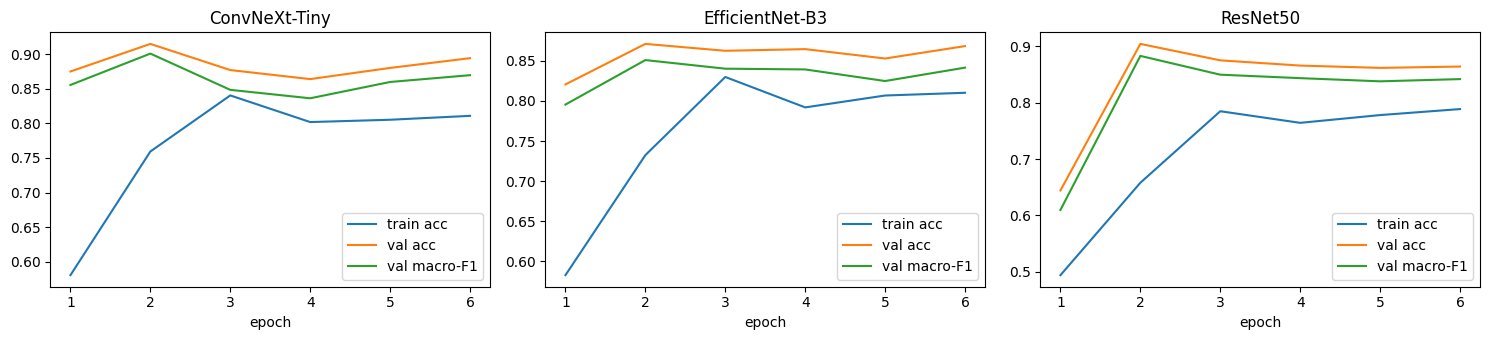

In [8]:
hist_files = sorted(OUT_DIR.glob("*_history.csv"))
fig, axes = plt.subplots(1, len(hist_files), figsize=(5 * len(hist_files), 3.5), squeeze=False)
for ax, f in zip(axes[0], hist_files):
    h = pd.read_csv(f)
    ax.plot(h.epoch, h.train_acc, label="train acc"); ax.plot(h.epoch, h.val_acc, label="val acc")
    ax.plot(h.epoch, h.val_f1, label="val macro-F1"); ax.set_title(f.stem.replace("_history", "")); ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "figures/learning_curves.png", dpi=150); plt.show()

## 7. Ensembles

In [9]:
y_val, y_test = val_df.label.values, test_df.label.values
singles = list(test_probs)
for r in range(2, len(BACKBONES) + 1):
    for combo in combinations(BACKBONES, r):
        for suffix in ["", " + AdaBN"]:
            keys = [k + suffix if k + suffix in test_probs else k for k in combo]
            if suffix and keys == list(combo):
                continue
            if all(k in test_probs for k in keys):
                name = "Ensemble(" + " + ".join(combo) + ")" + suffix
                val_probs[name] = np.mean([val_probs[k] for k in keys], 0)
                test_probs[name] = np.mean([test_probs[k] for k in keys], 0)
print(f"{len(test_probs)} variants evaluated")

13 variants evaluated


## 8. Results: All Variants (Validation and Test)

In [10]:
def metrics(y, prob):
    pred = prob.argmax(1)
    P, R, F, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    try:
        auc = roc_auc_score(label_binarize(y, classes=range(NUM_CLASSES)), prob, average="macro")
    except ValueError:
        auc = np.nan
    return dict(accuracy=accuracy_score(y, pred), precision_macro=P, recall_macro=R, f1_macro=F,
                balanced_acc=balanced_accuracy_score(y, pred), roc_auc_macro=auc,
                kappa=cohen_kappa_score(y, pred), mcc=matthews_corrcoef(y, pred))

rows = []
for k in test_probs:
    v, t = metrics(y_val, val_probs[k]), metrics(y_test, test_probs[k])
    rows.append({"variant": k, "val_acc": v["accuracy"], "val_f1": v["f1_macro"],
                 **{f"test_{m}": x for m, x in t.items()}})
table = pd.DataFrame(rows).set_index("variant").sort_values("val_f1", ascending=False)
table.to_csv(OUT_DIR / "all_variants.csv")
display(table.round(4))

,val_acc,val_f1,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_balanced_acc,test_roc_auc_macro,test_kappa,test_mcc
variant,,,,,,,,,,
Ensemble(ResNet50 + ConvNeXt-Tiny),0.9237,0.9084,0.8402,0.8704,0.8812,0.8546,0.8812,0.9723,0.7875,0.8058
ResNet50,0.9186,0.8981,0.7460,0.8300,0.8162,0.7684,0.8162,0.9491,0.6698,0.7167
ConvNeXt-Tiny,0.9107,0.8956,0.8607,0.8751,0.8889,0.8710,0.8889,0.9680,0.8129,0.8222
Ensemble(ResNet50 + EfficientNet-B3 + ConvNeXt-Tiny),0.9034,0.8860,0.8110,0.8668,0.8668,0.8302,0.8668,0.9762,0.7513,0.7833
Ensemble(ResNet50 + ConvNeXt-Tiny) + AdaBN,0.9017,0.8837,0.7510,0.7953,0.8132,0.7679,0.8132,0.9690,0.6702,0.7009
Ensemble(EfficientNet-B3 + ConvNeXt-Tiny),0.8959,0.8792,0.8400,0.8745,0.8830,0.8550,0.8830,0.9749,0.7875,0.8080
Ensemble(EfficientNet-B3 + ConvNeXt-Tiny) + AdaBN,0.8969,0.8784,0.8206,0.8618,0.8679,0.8377,0.8679,NaN,0.7625,0.7862
Ensemble(ResNet50 + EfficientNet-B3 + ConvNeXt-Tiny) + AdaBN,0.8890,0.8683,0.7700,0.8105,0.8343,0.7817,0.8343,NaN,0.6976,0.7282
Ensemble(ResNet50 + EfficientNet-B3),0.8873,0.8668,0.7533,0.8473,0.8278,0.7765,0.8278,0.9688,0.6799,0.7321


## 9. Selected Model (Chosen on Validation Only)

In [11]:
best = table.index[0]
p = test_probs[best]
rng = np.random.default_rng(SEED); pred = p.argmax(1)
boot = [accuracy_score(y_test[i], pred[i]) for i in (rng.integers(0, len(y_test), len(y_test)) for _ in range(N_BOOTSTRAP))]
lo, hi = np.percentile(boot, [2.5, 97.5])
base = {}
for k in ["ResNet50", "EfficientNet-B3", "ConvNeXt-Tiny"]:
    f = SHARED / "predictions" / f"{k}.npz"
    if f.exists():
        base[f"Baseline {k} (notebook 0{list(BACKBONES).index(k) + 1})"] = accuracy_score(y_test, np.load(f)["prob"].argmax(1))
print(f"Selected on validation: {best}")
print(f"Test accuracy: {accuracy_score(y_test, pred):.4f}  (95% CI [{lo:.4f}, {hi:.4f}])")
for k, v in base.items():
    print(f"  {k}: {v:.4f}")
rep = pd.DataFrame(classification_report(y_test, pred, labels=range(NUM_CLASSES), target_names=NAMES,
                                         output_dict=True, zero_division=0)).T.loc[NAMES, ["precision", "recall", "f1-score", "support"]]
rep.to_csv(OUT_DIR / "selected_per_class.csv")
display(rep.round(4))

Selected on validation: Ensemble(ResNet50 + ConvNeXt-Tiny)
Test accuracy: 0.8402  (95% CI [0.8302, 0.8501])
  Baseline ResNet50 (notebook 01): 0.7324
  Baseline EfficientNet-B3 (notebook 02): 0.7371
  Baseline ConvNeXt-Tiny (notebook 03): 0.7616


,precision,recall,f1-score,support
Lack of Penetration,0.5446,0.9259,0.6858,877.0
Crack,0.9467,0.6144,0.7452,1735.0
Porosity,0.9921,0.9854,0.9887,890.0
No Defect,0.9983,0.9992,0.9987,1180.0


## 10. Confusion Matrix and Per-Weld Breakdown

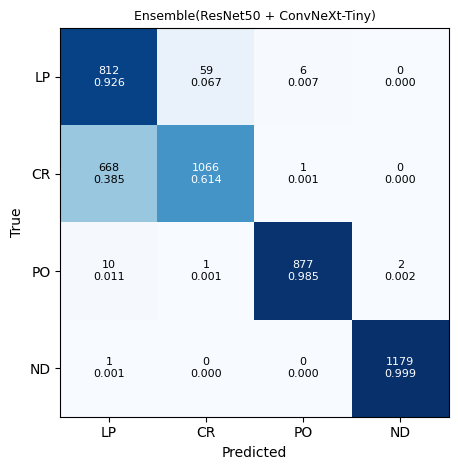

,weld,class_name,accuracy,n,errors
0,RRT-13R,Crack,0.6503,1590,556
6,RRT-40R,Crack,0.2207,145,113
3,RRT-26R,Lack of Penetration,0.9259,877,65
5,RRT-26R,Porosity,0.9804,459,9
9,RRT-98R,Porosity,0.9873,157,2
8,RRT-40R,Porosity,0.9901,203,2
7,RRT-40R,No Defect,0.9984,636,1
1,RRT-13R,No Defect,1.0000,191,0
4,RRT-26R,No Defect,1.0000,353,0
2,RRT-13R,Porosity,1.0000,71,0


In [12]:
cm = confusion_matrix(y_test, pred, labels=range(NUM_CLASSES))
cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.3f}", ha="center", va="center", fontsize=8,
                color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xticks(range(NUM_CLASSES), SHORT); ax.set_yticks(range(NUM_CLASSES), SHORT)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(best, fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "figures/confusion_matrix_selected.png", dpi=200); plt.show()

t = test_df.assign(correct=pred == y_test)
by_weld = (t.groupby(["weld", "class_name"]).correct.agg(accuracy="mean", n="size").reset_index()
           .assign(errors=lambda d: ((1 - d.accuracy) * d.n).round().astype(int)).sort_values("errors", ascending=False))
by_weld.to_csv(OUT_DIR / "selected_per_weld.csv", index=False)
display(by_weld.head(10).round(4))

## 11. Export Summary

In [13]:
summary = dict(protocol=PROTOCOL, input_mode=INPUT_MODE, weld_balanced=WELD_BALANCED, mixup_alpha=MIXUP_ALPHA,
               epochs=EPOCHS, batch_size=BATCH_SIZE, adabn=USE_ADABN, selected_variant=best,
               selected_test_accuracy=float(accuracy_score(y_test, pred)), accuracy_95ci=[float(lo), float(hi)],
               baselines=base, note="AdaBN variants re-estimate BatchNorm statistics on unlabeled images of the evaluated split; no labels are used.")
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print("Saved to", OUT_DIR.resolve())

Saved to C:\Users\dipkh\Downloads\RIAWLC\3\riawelc_outputs\weld_holdout\improved_dual
